# Proyek A — Multilabel Text Classification
**Kelompok:** KelpNLP: Edward Christian Imanuel Tambunan (240712822), Samuel Viva Gracia (240712828), Rhiquelshen Charolim (240712846)
**Topik:** Jenis serangan verbal pada komentar berita polemik KPAI vs PB Djarum

Notebook ini membangun model yang menerima satu komentar dan menghasilkan satu atau lebih label serangan:
`INSULTING`, `MOCKING`, `ACCUSING`, `PROVOKING`, `CURSING`. Jika tidak ada serangan, labelnya `NONE`.

Alur notebook:
1. **Data preparation** — membaca gold dataset, validasi, multilabel encoding, cek imbalance, split train/val/test tanpa leakage
2. EDA multilabel
3. Representasi teks dan model
4. Evaluasi dan error analysis
5. Menyimpan model terbaik

## 1. Setup
Memuat library, menentukan lokasi folder proyek, dan menetapkan konstanta yang dipakai di seluruh notebook.

In [2]:
import json, re, hashlib, platform
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

pd.set_option("display.max_colwidth", 80)

# ---------- lokasi folder proyek ----------
# Notebook ada di folder notebook/, jadi ROOT = folder di atasnya.
# Dicari otomatis supaya notebook tetap jalan walau dibuka dari folder lain.
ROOT = Path.cwd()
while not (ROOT / "dataset" / "gold").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "dataset" / "gold").exists(), "Folder proyek tidak ditemukan"

GOLD_PATH = ROOT / "dataset" / "gold" / "KelpNLP_dataset_annotation.jsonl"
DATA_DIR = ROOT / "dataset"
SHA_GOLD_RILIS = "8a8a77faa4fb7aa76b6d3d178cbc62fa4138525411bd80ab3971910ec6138b3d"

# ---------- konstanta ----------
SEED = 42                       # seed umum (model, sampling)
ATTACK_LABELS = ["INSULTING", "MOCKING", "ACCUSING", "PROVOKING", "CURSING"]
ALL_LABELS = ATTACK_LABELS + ["NONE"]
ENTITY_TYPES = ["GOV_ORG", "NONGOV_ORG", "PERSON", "GROUP"]
SPLIT_RATIO = {"train": 0.70, "val": 0.15, "test": 0.15} # rasio split dataset sesuai ketentuan 70% Train, 15% Val, 15% Test
NEAR_DUP_THRESHOLD = 0.75       # batas kemiripan teks hampir-duplikat
N_CANDIDATE_SEEDS = 20          # jumlah kandidat seed split

np.random.seed(SEED)

print("ROOT    :", ROOT)
print("Python  :", platform.python_version())
for lib in (np, pd, sklearn):
    print(f"{lib.__name__:8s}:", lib.__version__)

ROOT    : d:\Kuliah\Semester 5\NLP\KelpNLP_UAS
Python  : 3.12.10
numpy   : 2.5.5
pandas  : 3.1.1
sklearn : 1.9.1


## 2. Data Loading & Validation
Gold dataset dibaca dari file eksternal hasil UTS (`dataset/gold/KelpNLP_dataset_annotation.jsonl`).
Sebelum dipakai, kami memastikan file ini **sama persis** dengan rilis UTS lewat SHA-256. Kalau ada satu karakter saja yang berubah, nilai SHA-nya akan berbeda dan notebook berhenti.

In [3]:
# Cek file gold sama persis dengan rilis UTS (SHA-256)
sha = hashlib.sha256(GOLD_PATH.read_bytes()).hexdigest()
print("SHA-256 :", sha)
assert sha == SHA_GOLD_RILIS, "File gold berbeda dari rilis UTS!"
print("OK - file gold sama dengan rilis UTS")

# Baca JSONL: satu baris = satu teks
with open(GOLD_PATH, encoding="utf-8") as f:
    records = [json.loads(line) for line in f]

gold = pd.DataFrame({
    "id":     [r["id"] for r in records],
    "text":   [r["text"] for r in records],
    "labels": [r["labels"] for r in records],
    "spans":  [r["spans"] for r in records],
    "thread": [r["meta"]["thread"] for r in records],
})
print("Jumlah teks :", len(gold))
print("Kolom JSONL :", list(records[0].keys()))
gold.head()

SHA-256 : 8a8a77faa4fb7aa76b6d3d178cbc62fa4138525411bd80ab3971910ec6138b3d
OK - file gold sama dengan rilis UTS
Jumlah teks : 999
Kolom JSONL : ['id', 'text', 'meta', 'labels', 'spans', 'tokens', 'ner_bio', 'annotations', 'adjudication']


,id,text,labels,spans,thread
0,ANC-1123,"Mungkin dia survei ke anaknya sendiri yang gak lolos seleksi, jadinya ada sa...",[ACCUSING],[],1
1,ANC-1124,"KPAI bicara ketulusan, coba cek ketulusan KPAI ini, berani sumbangkan gaji m...",[MOCKING],"[{'start': 0, 'end': 4, 'label': 'GOV_ORG', 'text': 'KPAI'}, {'start': 42, '...",1
2,ANC-1128,"KPAI mungkin survey dgn bbrp orang yg gagal lolos audisi, jd nya gitu dah. A...",[NONE],"[{'start': 0, 'end': 4, 'label': 'GOV_ORG', 'text': 'KPAI'}]",1
3,ANC-1129,muiinnyakkkkk dulu gan,[NONE],[],1
4,ANC-1131,"Mungkin niatnya baik KPAI, cuman kurang main cantik n elegan aja",[NONE],"[{'start': 21, 'end': 25, 'label': 'GOV_ORG', 'text': 'KPAI'}]",1


Berikutnya, kualitas data diperiksa satu per satu. Setiap pemeriksaan ditulis sebagai `assert`, jadi kalau ada yang gagal notebook langsung berhenti dan tidak diam-diam memakai data yang salah.

In [4]:
# ---------- validasi struktur dan kualitas ----------
cek = {}

# 1. jumlah data sesuai gold UTS
cek["jumlah teks = 999"] = len(gold) == 999
# 2. tidak ada nilai kosong
cek["tidak ada missing value"] = not gold[["id", "text", "labels"]].isna().any().any()
cek["tidak ada teks kosong"] = (gold["text"].str.strip() != "").all()
# 3. ID unik
cek["ID unik"] = gold["id"].is_unique
# 4. tidak ada duplikat teks persis (setelah huruf kecil + rapikan spasi)
text_norm = gold["text"].str.lower().str.split().str.join(" ")
cek["tidak ada duplikat teks persis"] = text_norm.is_unique
# 5. format label: list, tidak kosong, hanya dari taxonomy
cek["labels berupa list"] = gold["labels"].map(lambda x: isinstance(x, list)).all()
cek["setiap teks punya >= 1 label"] = (gold["labels"].str.len() > 0).all()
cek["label hanya dari taxonomy"] = gold["labels"].map(lambda x: set(x) <= set(ALL_LABELS)).all()
cek["tidak ada label ganda dalam satu teks"] = gold["labels"].map(lambda x: len(x) == len(set(x))).all()
# 6. aturan guideline: NONE tidak boleh bersama label lain
cek["NONE tidak bercampur label lain"] = gold["labels"].map(lambda x: "NONE" not in x or len(x) == 1).all()
# 7. utas berita hanya 1, 2, 3
cek["utas berita valid (1/2/3)"] = gold["thread"].isin([1, 2, 3]).all()

hasil_cek = pd.DataFrame({"pemeriksaan": list(cek), "lolos": list(cek.values())})
display(hasil_cek)
assert all(cek.values()), "Ada pemeriksaan yang gagal, cek tabel di atas"
print("Semua pemeriksaan lolos")

,pemeriksaan,lolos
0,jumlah teks = 999,True
1,tidak ada missing value,True
2,tidak ada teks kosong,True
3,ID unik,True
4,tidak ada duplikat teks persis,True
5,labels berupa list,True
6,setiap teks punya >= 1 label,True
7,label hanya dari taxonomy,True
8,tidak ada label ganda dalam satu teks,True
9,NONE tidak bercampur label lain,True


Semua pemeriksaan lolos


In [5]:
# Statistik dasar
n_words = gold["text"].str.split().str.len()
n_chars = gold["text"].str.len()
stat = pd.DataFrame({"kata": n_words.describe(percentiles=[.5, .9, .95, .99]),
                     "karakter": n_chars.describe(percentiles=[.5, .9, .95, .99])}).round(1)
display(stat)
print("Jumlah teks per utas berita:")
display(gold["thread"].value_counts().sort_index().rename("jumlah teks").to_frame())

,kata,karakter
count,999.0,999.0
mean,23.7,153.2
std,26.4,171.3
min,1.0,12.0
50%,17.0,109.0
90%,47.0,298.2
95%,62.0,406.3
99%,122.2,773.7
max,486.0,3159.0


Jumlah teks per utas berita:


,jumlah teks
thread,
1,118
2,263
3,618


**Interpretasi**
- File gold **sama persis** dengan rilis UTS (SHA cocok), jadi data yang dipakai di UAS memang hasil anotasi dan adjudikasi UTS, tanpa perubahan.
- Ada **999 teks**, dan **11 pemeriksaan lolos semua**: tidak ada data kosong, tidak ada ID kembar, tidak ada teks yang persis sama, semua label berasal dari taxonomy, dan `NONE` tidak pernah muncul bersama label lain. Data siap dipakai tanpa perbaikan.
- Panjang komentar sangat bervariasi. Separuh komentar hanya **17 kata atau kurang**, 95% di bawah **62 kata**, tapi ada satu komentar sepanjang **486 kata**. Ini penting nanti saat memilih panjang input maksimum untuk IndoBERT.
- Komentar paling banyak berasal dari **utas 3** (618 teks), lalu utas 2 (263) dan utas 1 (118). Karena itu utas berita ikut dijaga proporsinya saat split, supaya train, val, dan test sama-sama mewakili ketiga berita.

## 3. Multilabel Encoding
Label di gold berbentuk list, misalnya `["INSULTING", "ACCUSING"]`. Model butuh bentuk angka, jadi setiap label diubah menjadi satu kolom bernilai 0/1 (*one-hot multilabel*) dengan `MultiLabelBinarizer`. Urutan kolom dikunci supaya selalu sama di train, val, test, dan aplikasi.

Model hanya memprediksi **5 label serangan**. `NONE` tidak dijadikan output terpisah, tetapi **diturunkan**: kalau tidak ada satu pun label serangan, hasilnya `NONE`. Dengan cara ini aturan guideline "NONE tidak boleh bersama label lain" otomatis selalu terpenuhi.

In [6]:
# ---------- multilabel encoding ----------
# Urutan kelas dikunci supaya kolom selalu sama di train, val, test, dan aplikasi
mlb = MultiLabelBinarizer(classes=ATTACK_LABELS)
attack_only = gold["labels"].map(lambda x: [l for l in x if l != "NONE"])
Y = mlb.fit_transform(attack_only)

y_df = pd.DataFrame(Y, columns=ATTACK_LABELS, index=gold.index)
# NONE diturunkan: tidak ada satu pun label serangan
y_df["NONE"] = (y_df[ATTACK_LABELS].sum(axis=1) == 0).astype(int)

# Cek: NONE hasil turunan harus sama persis dengan NONE di gold
none_gold = gold["labels"].map(lambda x: "NONE" in x).astype(int)
assert (y_df["NONE"] == none_gold).all()
print("OK - NONE turunan sama dengan NONE di gold untuk", len(gold), "teks")

data = pd.concat([gold[["id", "text", "thread"]], y_df], axis=1)
data["labels"] = gold["labels"].map(lambda x: "|".join(x))
data.head()

OK - NONE turunan sama dengan NONE di gold untuk 999 teks


,id,text,thread,INSULTING,MOCKING,ACCUSING,PROVOKING,CURSING,NONE,labels
0,ANC-1123,"Mungkin dia survei ke anaknya sendiri yang gak lolos seleksi, jadinya ada sa...",1,0,0,1,0,0,0,ACCUSING
1,ANC-1124,"KPAI bicara ketulusan, coba cek ketulusan KPAI ini, berani sumbangkan gaji m...",1,0,1,0,0,0,0,MOCKING
2,ANC-1128,"KPAI mungkin survey dgn bbrp orang yg gagal lolos audisi, jd nya gitu dah. A...",1,0,0,0,0,0,1,NONE
3,ANC-1129,muiinnyakkkkk dulu gan,1,0,0,0,0,0,1,NONE
4,ANC-1131,"Mungkin niatnya baik KPAI, cuman kurang main cantik n elegan aja",1,0,0,0,0,0,1,NONE


In [7]:
# Contoh hasil encoding: satu teks per jumlah label
contoh = data.assign(n_label=data[ATTACK_LABELS].sum(axis=1))
contoh = contoh.groupby("n_label").head(1).sort_values("n_label")
contoh[["id", "text", "labels"] + ALL_LABELS]

,id,text,labels,INSULTING,MOCKING,ACCUSING,PROVOKING,CURSING,NONE
2,ANC-1128,"KPAI mungkin survey dgn bbrp orang yg gagal lolos audisi, jd nya gitu dah. A...",NONE,0,0,0,0,0,1
0,ANC-1123,"Mungkin dia survei ke anaknya sendiri yang gak lolos seleksi, jadinya ada sa...",ACCUSING,0,0,1,0,0,0
23,ANC-1157,"KPAI sedang cari sensasi nih.... kemeren bulu tangkis yg di usik, habis itu ...",ACCUSING|MOCKING,0,1,1,0,0,0
47,ANC-1191,"KPAI survei ke anak2 onta gurun mungkin, dasar KPAI totol Kalo ada petisi pe...",INSULTING|ACCUSING|MOCKING,1,1,1,0,0,0
196,ANC-1724,"saya penggemar PB. Jarum dalam hal badmintonnya, tapi saya enggak merokok, m...",INSULTING|ACCUSING|MOCKING|PROVOKING,1,1,1,1,0,0


**Interpretasi**
- Encoding berhasil. `NONE` hasil turunan **sama persis** dengan `NONE` di gold untuk ke-999 teks, jadi menurunkan NONE dari "tidak ada label serangan" tidak mengubah data sedikit pun.
- Tabel contoh memperlihatkan bentuk multilabel. Satu komentar bisa punya 0 label serangan (NONE) sampai 4 label sekaligus, misalnya ANC-1724 yang berlabel INSULTING, ACCUSING, MOCKING, dan PROVOKING. Inilah alasan tugas ini disebut *multilabel*, bukan *multiclass*.

## 4. Pemeriksaan Label Imbalance
Kami menghitung seberapa sering setiap label muncul. Ukuran yang dipakai:
- **rasio neg:pos** — berapa teks *tanpa* label itu untuk setiap satu teks *dengan* label itu;
- **IRLbl** (*imbalance ratio per label*) — frekuensi label terbanyak dibagi frekuensi label ini (1 = paling banyak; makin besar makin langka);
- **MeanIR** — rata-rata IRLbl; di atas 1,5 biasanya dianggap timpang;
- **label cardinality** — rata-rata jumlah label per teks.

,jumlah positif,% teks,rasio neg:pos,IRLbl
INSULTING,364,36.4,1.7,1.02
MOCKING,332,33.2,2.0,1.11
ACCUSING,370,37.0,1.7,1.00
PROVOKING,168,16.8,4.9,2.20
CURSING,7,0.7,141.7,52.86
NONE,181,18.1,4.5,NaN


Label cardinality (rata-rata label serangan per teks): 1.242
Label density                                       : 0.248
Teks multilabel (>= 2 label)                        : 353 (35.3%)
MeanIR 5 label                                      : 11.64
MeanIR tanpa CURSING                                : 1.33


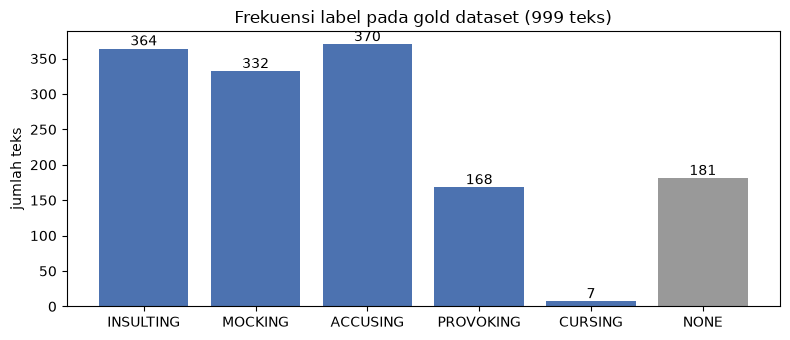

In [8]:
# ---------- pemeriksaan label imbalance ----------
n = len(data)
freq = data[ALL_LABELS].sum()
imb = pd.DataFrame({
    "jumlah positif": freq,
    "% teks": (freq / n * 100).round(1),
    "rasio neg:pos": ((n - freq) / freq).round(1),
})
# IRLbl = frekuensi label terbanyak / frekuensi label ini (1 = paling banyak)
imb["IRLbl"] = (freq[ATTACK_LABELS].max() / freq).round(2)
imb.loc["NONE", "IRLbl"] = np.nan          # NONE bukan output model
display(imb)

card = data[ATTACK_LABELS].sum(axis=1)
mean_ir = imb.loc[ATTACK_LABELS, "IRLbl"].mean()
mean_ir_4 = imb.loc[ATTACK_LABELS[:4], "IRLbl"].mean()
print(f"Label cardinality (rata-rata label serangan per teks): {card.mean():.3f}")
print(f"Label density                                       : {card.mean() / len(ATTACK_LABELS):.3f}")
print(f"Teks multilabel (>= 2 label)                        : {(card >= 2).sum()} ({(card >= 2).mean():.1%})")
print(f"MeanIR 5 label                                      : {mean_ir:.2f}")
print(f"MeanIR tanpa CURSING                                : {mean_ir_4:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(ALL_LABELS, freq[ALL_LABELS], color=["#4C72B0"] * 5 + ["#999999"])
ax.bar_label(bars)
ax.set_ylabel("jumlah teks")
ax.set_title("Frekuensi label pada gold dataset (999 teks)")
plt.tight_layout(); plt.show()

**Interpretasi**
- **ACCUSING (370), INSULTING (364), dan MOCKING (332)** jumlahnya hampir sama, masing-masing muncul di sekitar sepertiga komentar.
- **PROVOKING (168)** dua kali lebih jarang (IRLbl 2,20). Untuk setiap komentar PROVOKING ada sekitar 5 komentar yang bukan PROVOKING.
- **CURSING hanya 7 teks (0,7%)**, IRLbl 52,86. Label ini hampir tidak mungkin dipelajari model. Label tetap dipertahankan karena taxonomy UTS tidak boleh diubah (spesifikasi 6.1), tetapi hasilnya dilaporkan terpisah dan macro-F1 dihitung dua versi: 5 label dan 4 label tanpa CURSING.
- **MeanIR 5 label = 11,64**, tapi tanpa CURSING hanya **1,33**. Artinya ketimpangan ekstrem hanya disebabkan CURSING; empat label lainnya cukup seimbang.
- Rata-rata ada **1,24 label serangan per teks**, dan **35,3% teks punya ≥ 2 label**. Bagian multilabelnya cukup besar, jadi split harus menjaga kombinasi label (*multilabel stratification*), tidak cukup dengan split acak biasa.
- Dampak ke pemodelan: label minoritas perlu diberi bobot lebih besar saat training (`class_weight="balanced"`, atau `pos_weight` untuk IndoBERT), dan model dinilai dengan F1 per label serta macro-F1, bukan accuracy saja.

## 5. Pencegahan Leakage: Deteksi Hampir-Duplikat
Duplikat persis sudah tidak ada (pemeriksaan di bagian 2). Tetapi komentar yang **hampir sama** (mis. `#bubarkankpai` dan `BubarkanKPAI !`) tetap berbahaya: kalau satu masuk train dan satunya masuk test, model seperti "sudah melihat soal ujian", sehingga skor test terlihat lebih bagus dari kenyataan.

Caranya:
1. teks dinormalisasi (huruf kecil, tanda baca jadi spasi);
2. kemiripan antar-teks dihitung dengan TF-IDF n-gram karakter dan *cosine similarity*;
3. pasangan dengan cosine ≥ 0,75 digabung menjadi satu **kelompok**, dan satu kelompok selalu masuk split yang sama.

TF-IDF di sini hanya alat untuk mencari teks mirip, bukan fitur model, jadi menghitungnya dari seluruh data tidak menimbulkan leakage.

In [9]:
# ---------- deteksi hampir-duplikat ----------
def normalize_for_dup(t):
    # huruf kecil, semua tanda baca/simbol jadi spasi
    return re.sub(r"\W+", " ", t.lower()).strip()

vec_dup = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))
X_dup = vec_dup.fit_transform(gold["text"].map(normalize_for_dup))
sim = cosine_similarity(X_dup)
np.fill_diagonal(sim, 0)

ii, jj = np.where(np.triu(sim) >= NEAR_DUP_THRESHOLD)
pairs = pd.DataFrame({
    "id_1": gold["id"].values[ii], "id_2": gold["id"].values[jj],
    "cosine": sim[ii, jj].round(3),
    "teks_1": gold["text"].values[ii], "teks_2": gold["text"].values[jj],
    "label_1": data["labels"].values[ii], "label_2": data["labels"].values[jj],
}).sort_values("cosine", ascending=False).reset_index(drop=True)
print(f"Pasangan dengan cosine >= {NEAR_DUP_THRESHOLD}: {len(pairs)}")
pairs

Pasangan dengan cosine >= 0.75: 11


,id_1,id_2,cosine,teks_1,teks_2,label_1,label_2
0,ANC-1276,ANC-1701,1.000,#bubarkankpai,BubarkanKPAI !,PROVOKING,PROVOKING
1,ANC-2265,ANC-2266,0.998,"Kepada Para Pejabat Di KPAI , saya mau menanyakan beberapa hal antara lain :...","Kepada Para Pejabat Di KPAI , saya mau menanyakan beberapa hal antara lain :...",NONE,NONE
2,ANC-2563,ANC-3025,0.986,KPAI = KOMISI PERUSAK ANAK INDONESIA,KOMISI PERUSAK ANAK INDONESIA,MOCKING,MOCKING
3,ANC-3003,ANC-3011,0.922,mohon proses recruitment anggota dan pimpinan lembaga non kementerian dilaks...,mohon proses recruitment anggota dan pimpinan lembaga non kementerian dilaks...,NONE,NONE
4,ANC-1180,ANC-2871,0.844,ke anak kampret dong,KPAI KAMPRET !!!,INSULTING,INSULTING
5,ANC-2889,ANC-3127,0.825,Cuci tangan...,ah cuci tangan deh,ACCUSING,ACCUSING
6,ANC-1686,ANC-3114,0.800,"Bubarkan KPAI, lembaga nggak guna!",Bubarkan KPAI lembaga tak ada guna,INSULTING|PROVOKING,INSULTING|PROVOKING
7,ANC-1696,ANC-1974,0.779,#bubarkanKPI,#bubarkanKPAI #bubarkanKPI lembaga sampah,PROVOKING,INSULTING|PROVOKING
8,ANC-3109,ANC-3111,0.776,kurang kerjaan atau kurang jatah ya,KPAI kurang kerjaan,INSULTING|ACCUSING,INSULTING
9,ANC-1276,ANC-1974,0.755,#bubarkankpai,#bubarkanKPAI #bubarkanKPI lembaga sampah,PROVOKING,INSULTING|PROVOKING


In [10]:
# Gabungkan pasangan menjadi kelompok (union-find).
# Teks dalam satu kelompok nanti selalu masuk split yang sama.
parent = list(range(n))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for a, b in zip(ii, jj):
    parent[find(a)] = find(b)

data["group"] = [find(i) for i in range(n)]
group_size = data["group"].map(data["group"].value_counts())
print("Jumlah unit (kelompok) :", data["group"].nunique())
print("Kelompok berisi > 1 teks:", (data.groupby("group").size() > 1).sum())
data.loc[group_size > 1].sort_values("group")[["id", "text", "labels", "group"]]

Jumlah unit (kelompok) : 989
Kelompok berisi > 1 teks: 8


,id,text,labels,group
103,ANC-1276,#bubarkankpai,PROVOKING,363
177,ANC-1696,#bubarkanKPI,PROVOKING,363
363,ANC-1974,#bubarkanKPAI #bubarkanKPI lembaga sampah,INSULTING|PROVOKING,363
180,ANC-1701,BubarkanKPAI !,PROVOKING,363
398,ANC-2265,"Kepada Para Pejabat Di KPAI , saya mau menanyakan beberapa hal antara lain :...",NONE,399
399,ANC-2266,"Kepada Para Pejabat Di KPAI , saya mau menanyakan beberapa hal antara lain :...",NONE,399
41,ANC-1180,ke anak kampret dong,INSULTING,793
793,ANC-2871,KPAI KAMPRET !!!,INSULTING,793
882,ANC-3011,mohon proses recruitment anggota dan pimpinan lembaga non kementerian dilaks...,NONE,882
877,ANC-3003,mohon proses recruitment anggota dan pimpinan lembaga non kementerian dilaks...,NONE,882


**Interpretasi**
- Ada **11 pasangan** komentar yang hampir sama. Empat di antaranya praktis kembar: ANC-1276 `#bubarkankpai` dan ANC-1701 `BubarkanKPAI !` (cosine 1,000), ANC-2265 dan ANC-2266 (0,998), ANC-2563 dan ANC-3025 (0,986), serta ANC-3003 dan ANC-3011 (0,922).
- Sisanya mirip karena kalimatnya hampir sama, misalnya "Bubarkan KPAI, lembaga nggak guna!" dan "Bubarkan KPAI lembaga tak ada guna". Ada juga pasangan yang sebenarnya hanya bertema sama, seperti "ke anak kampret dong" dan "KPAI KAMPRET !!!". Pasangan seperti ini tetap kami kelompokkan karena menggabungkan terlalu banyak tidak merugikan, sedangkan menggabungkan terlalu sedikit bisa membuat data bocor.
- Hasilnya **989 unit**, dengan **8 kelompok** berisi lebih dari satu teks. Kelompok terbesar berisi 4 komentar tagar `#bubarkanKPAI`/`#bubarkanKPI`.
- Pasangan mirip umumnya berlabel sama (mis. keduanya PROVOKING), jadi kalau terpisah ke train dan test, model akan terlihat lebih pintar dari aslinya. Pengelompokan ini mencegah hal tersebut.

## 6. Split Train / Validation / Test
Proporsi mengikuti saran spesifikasi: **70% train, 15% validation, 15% test**.
- **Train** untuk melatih model, **validation** untuk memilih hyperparameter, threshold, dan model terbaik, **test** hanya dipakai **sekali** di akhir untuk evaluasi.
- Split dilakukan dengan **iterative stratification** (`iterstrat`), yaitu stratifikasi khusus multilabel. Tujuannya agar proporsi setiap label hampir sama di ketiga split, padahal satu teks bisa punya banyak label.
- Split dilakukan di tingkat **kelompok** dari bagian 5, dalam dua tahap: 70 | 30, lalu 30 dibagi 15 | 15.

**Kunci stratifikasi.** Selain 5 label + NONE dan utas berita, distribusi **entitas** juga ikut dijaga. Alasannya, split yang sama akan dipakai notebook NER, karena spesifikasi 6.4 meminta kedua model dibandingkan pada teks test yang sama.

**Pemilihan seed.** Hasil split cukup bergantung pada seed. Karena itu kami mencoba **20 kandidat seed** dan memilih yang paling seimbang. Kriterianya ditetapkan **sebelum** ada model yang dilatih: nilai terkecil dari deviasi maksimum (poin persen) untuk proporsi label, porsi entitas, dan ukuran split. Karena belum ada model yang dilihat, pemilihan ini tidak membocorkan informasi test.

In [11]:
# ---------- kunci stratifikasi ----------
# Split ini dipakai juga oleh notebook NER (spesifikasi 6.4 membandingkan
# kedua model pada teks test yang sama), jadi distribusi entitas ikut dijaga.
ent_count = pd.DataFrame(
    [{e: sum(s["label"] == e for s in sp) for e in ENTITY_TYPES} for sp in gold["spans"]],
    index=gold.index)

strat = pd.concat([
    data[ALL_LABELS],                                                   # 5 label + NONE
    pd.get_dummies(data["thread"], prefix="utas").astype(int),          # utas berita
    (ent_count > 0).astype(int).add_prefix("ada_"),                     # ada tipe entitas
    (ent_count >= 2).astype(int).add_prefix("banyak_"),                 # >= 2 entitas per tipe
    (ent_count.sum(axis=1) >= 4).astype(int).rename("entitas_4plus"),   # teks padat entitas
], axis=1)

# Satu baris per kelompok (nilai 1 jika salah satu anggotanya bernilai 1)
group_ids = np.array(sorted(data["group"].unique()))
strat_group = strat.groupby(data["group"]).max().loc[group_ids]
print("Kolom kunci stratifikasi:", strat.shape[1])
print(list(strat.columns))

Kolom kunci stratifikasi: 18
['INSULTING', 'MOCKING', 'ACCUSING', 'PROVOKING', 'CURSING', 'NONE', 'utas_1', 'utas_2', 'utas_3', 'ada_GOV_ORG', 'ada_NONGOV_ORG', 'ada_PERSON', 'ada_GROUP', 'banyak_GOV_ORG', 'banyak_NONGOV_ORG', 'banyak_PERSON', 'banyak_GROUP', 'entitas_4plus']


In [12]:
def make_split(seed):
    """Split 70/15/15 di tingkat kelompok, dua tahap: 70|30, lalu 30 -> 15|15."""
    Xg = np.zeros(len(group_ids))                 # iterstrat hanya butuh jumlah baris
    Yg = strat_group.values
    s1 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=seed)
    tr, rest = next(s1.split(Xg, Yg))
    s2 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=seed)
    va, te = next(s2.split(Xg[rest], Yg[rest]))
    va, te = rest[va], rest[te]
    g2s = {}
    for name, idx in (("train", tr), ("val", va), ("test", te)):
        g2s.update({g: name for g in group_ids[idx]})
    return data["group"].map(g2s).values

total_ent = ent_count.sum()
def split_quality(split):
    """Deviasi maksimum (poin persen) dari kondisi ideal."""
    dev_label = dev_ent = dev_size = 0
    for name, target in SPLIT_RATIO.items():
        m = split == name
        dev_size = max(dev_size, abs(m.mean() - target) * 100)
        dev_label = max(dev_label, (data.loc[m, ALL_LABELS].mean() - data[ALL_LABELS].mean()).abs().max() * 100)
        dev_ent = max(dev_ent, (ent_count[m].sum() / total_ent - m.mean()).abs().max() * 100)
    return dev_label, dev_ent, dev_size

rows = []
for seed in range(N_CANDIDATE_SEEDS):
    sp = make_split(seed)
    dl, de, ds = split_quality(sp)
    rows.append({"seed": seed,
                 "train": (sp == "train").sum(), "val": (sp == "val").sum(), "test": (sp == "test").sum(),
                 "dev_label_pp": dl, "dev_entitas_pp": de, "dev_ukuran_pp": ds,
                 "skor": max(dl, de, ds)})
kandidat = pd.DataFrame(rows).round(2).sort_values(["skor", "seed"]).reset_index(drop=True)
SPLIT_SEED = int(kandidat.loc[0, "seed"])
print("Seed split terpilih:", SPLIT_SEED)
kandidat.head(10)

Seed split terpilih: 14


,seed,train,val,test,dev_label_pp,dev_entitas_pp,dev_ukuran_pp,skor
0,14,690,155,154,1.62,1.98,0.93,1.98
1,12,694,152,153,1.03,2.10,0.53,2.10
2,7,696,148,155,2.32,2.28,0.52,2.32
3,13,700,153,146,1.70,2.74,0.39,2.74
4,1,700,149,150,1.82,3.06,0.09,3.06
5,11,699,152,148,2.31,3.16,0.22,3.16
6,0,699,153,147,1.13,3.38,0.32,3.38
7,8,687,157,155,2.84,3.75,1.23,3.75
8,6,698,146,155,1.60,3.89,0.52,3.89
9,10,695,153,151,1.74,3.90,0.43,3.90


,n_teks,% teks,INSULTING,MOCKING,ACCUSING,PROVOKING,CURSING,NONE,GOV_ORG,NONGOV_ORG,PERSON,GROUP
split,,,,,,,,,,,,
train,690,69.1,254,233,258,118,5,127,587,360,47,542
val,155,15.5,54,49,55,24,1,27,130,74,11,110
test,154,15.4,56,50,57,26,1,27,129,83,9,123
total,999,100.0,364,332,370,168,7,181,846,517,67,775


,INSULTING,MOCKING,ACCUSING,PROVOKING,CURSING,NONE
% teks berlabel,,,,,,
train,36.8,33.8,37.4,17.1,0.7,18.4
val,34.8,31.6,35.5,15.5,0.6,17.4
test,36.4,32.5,37.0,16.9,0.6,17.5
semua,36.4,33.2,37.0,16.8,0.7,18.1


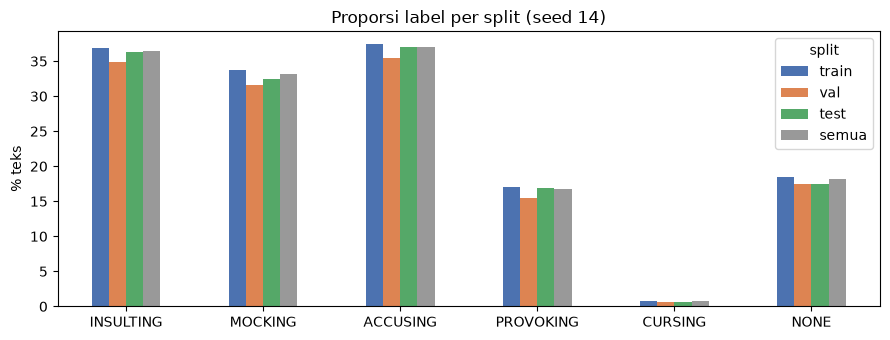

In [13]:
data["split"] = make_split(SPLIT_SEED)
order = ["train", "val", "test"]

ringkas = data.groupby("split")[ALL_LABELS].sum().loc[order]
ringkas.insert(0, "n_teks", data["split"].value_counts().loc[order])
ringkas.insert(1, "% teks", (ringkas["n_teks"] / n * 100).round(1))
ringkas = pd.concat([ringkas, ent_count.groupby(data["split"]).sum().loc[order]], axis=1)
ringkas.loc["total"] = ringkas.sum()
ringkas.loc["total", "% teks"] = 100.0
display(ringkas)

# proporsi label per split dibanding keseluruhan
prop = data.groupby("split")[ALL_LABELS].mean().loc[order] * 100
prop.loc["semua"] = data[ALL_LABELS].mean() * 100
display(prop.round(1).rename_axis("% teks berlabel"))

ax = prop.T.plot(kind="bar", figsize=(9, 3.5), color=["#4C72B0", "#DD8452", "#55A868", "#999999"])
ax.set_ylabel("% teks"); ax.set_title(f"Proporsi label per split (seed {SPLIT_SEED})")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Interpretasi**
- Dari 20 kandidat, **seed 14** paling seimbang. Deviasi maksimumnya hanya **1,62 poin persen** untuk proporsi label, **1,98** untuk porsi entitas, dan **0,93** untuk ukuran split. Seed terburuk di 10 besar deviasi entitasnya hampir dua kali lipat (3,90), jadi pemilihan seed memang berpengaruh.
- Hasil split: **690 train (69,1%), 155 val (15,5%), 154 test (15,4%)**. Ukurannya tidak tepat 699/150/150 karena kelompok hampir-duplikat tidak boleh dipecah. Penyimpangan kurang dari 1% ini harga yang wajar untuk mencegah leakage.
- Proporsi setiap label di ketiga split hampir sama dengan keseluruhan data. Contohnya INSULTING 36,8% / 34,8% / 36,4% dibanding 36,4% secara keseluruhan, dan NONE 18,4% / 17,4% / 17,5% dibanding 18,1%. Artinya val dan test mewakili kondisi data yang sama dengan train.
- **CURSING hanya 5 / 1 / 1 teks.** Dengan satu contoh di test, F1 CURSING hanya bisa bernilai 0 atau 1, jadi angka ini tidak bisa ditafsirkan sebagai kemampuan model. Keterbatasan ini ditulis apa adanya di laporan.
- Distribusi entitas juga seimbang (mis. GOV_ORG 587 / 130 / 129), sehingga split yang sama layak dipakai notebook NER.

## 7. Pemeriksaan Leakage Antar Split
Kami memastikan tidak ada data yang muncul di lebih dari satu split: ID yang sama, teks yang sama, atau kelompok hampir-duplikat yang terpecah. Sebagai transparansi, ditampilkan juga pasangan teks paling mirip yang masih tersisa antar split.

In [14]:
# ---------- pemeriksaan leakage antar split ----------
splits = {s: data[data["split"] == s] for s in order}
leak = {}
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    leak[f"ID sama {a}-{b}"] = len(set(splits[a]["id"]) & set(splits[b]["id"]))
    na = set(text_norm[splits[a].index]); nb = set(text_norm[splits[b].index])
    leak[f"teks sama {a}-{b}"] = len(na & nb)
# kelompok hampir-duplikat tidak boleh terpecah
leak["kelompok terpecah ke >1 split"] = int((data.groupby("group")["split"].nunique() > 1).sum())
display(pd.Series(leak, name="jumlah").to_frame())
assert sum(leak.values()) == 0, "Ada leakage!"

# kemiripan tertinggi yang tersisa antar split (untuk transparansi)
lintas = []
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    ia, ib = splits[a].index.values, splits[b].index.values
    s = sim[np.ix_(ia, ib)]
    k = np.unravel_index(s.argmax(), s.shape)
    lintas.append({"pasangan split": f"{a}-{b}", "cosine maks": round(s.max(), 3),
                   "id_1": data.loc[ia[k[0]], "id"], "teks_1": data.loc[ia[k[0]], "text"],
                   "id_2": data.loc[ib[k[1]], "id"], "teks_2": data.loc[ib[k[1]], "text"]})
assert len(set().union(*[set(d["id"]) for d in splits.values()])) == n
print("Tidak ada leakage. Gabungan ketiga split = seluruh", n, "teks.")
pd.DataFrame(lintas)

,jumlah
ID sama train-val,0
teks sama train-val,0
ID sama train-test,0
teks sama train-test,0
ID sama val-test,0
teks sama val-test,0
kelompok terpecah ke >1 split,0


Tidak ada leakage. Gabungan ketiga split = seluruh 999 teks.


,pasangan split,cosine maks,id_1,teks_1,id_2,teks_2
0,train-val,0.672,ANC-1293,kalo ada riset mana risetnya? di publish dong.. jgn state the obvious uu aja...,ANC-1163,iy.. mana kajian ilmiahnya bahwa ada eksploitasi? mana bukti2 nya? ngemeng a...
1,train-test,0.703,ANC-1963,"Bubarkan KPAI, gak ada gunanya nih lembaga",ANC-3114,Bubarkan KPAI lembaga tak ada guna
2,val-test,0.618,ANC-3139,KPAI lebay.. lembaga ngga ada guna,ANC-1686,"Bubarkan KPAI, lembaga nggak guna!"


**Interpretasi**
- Semua pemeriksaan bernilai **0**: tidak ada ID atau teks yang sama antar split, dan tidak ada kelompok hampir-duplikat yang terpecah. Gabungan ketiga split tepat 999 teks, jadi tidak ada data yang hilang atau terhitung dua kali.
- Kemiripan tertinggi yang tersisa antar split adalah **0,703**, antara ANC-1963 (train) "Bubarkan KPAI, gak ada gunanya nih lembaga" dan ANC-3114 (test) "Bubarkan KPAI lembaga tak ada guna". Nilainya di bawah ambang 0,75, dan kedua komentar ditulis orang berbeda dengan kata yang berbeda. Kemiripan seperti ini wajar karena banyak komentator memang menulis tuntutan yang sama ("bubarkan KPAI"), dan model memang perlu belajar mengenali pola itu.

## 8. Menyimpan File Split
Sesuai spesifikasi 6.6, split disimpan sebagai `KelpNLP_multilabel_train.csv`, `KelpNLP_multilabel_val.csv`, dan `KelpNLP_multilabel_test.csv` di folder `dataset/`.

| Kolom | Isi |
|---|---|
| `id` | ID komentar dari gold |
| `text` | teks komentar (sama persis dengan gold) |
| `thread` | utas berita (1/2/3) |
| `INSULTING` … `CURSING` | label serangan (0/1) — target model |
| `NONE` | 1 jika tidak ada label serangan (turunan) |
| `labels` | label dalam bentuk teks, dipisah `\|` |

Setelah disimpan, file dibaca ulang untuk memastikan teks dan label tidak berubah, lalu SHA-256 tiap file dicatat. Notebook NER nanti membaca ID dari file ini sehingga memakai split yang sama persis.

In [15]:
# ---------- simpan file split (spesifikasi 6.6) ----------
COLS = ["id", "text", "thread"] + ALL_LABELS + ["labels"]
saved = {}
for s in order:
    path = DATA_DIR / f"KelpNLP_multilabel_{s}.csv"
    splits[s][COLS].sort_values("id").to_csv(path, index=False, encoding="utf-8", lineterminator="\n")
    saved[s] = path

# Baca ulang dan pastikan isinya identik dengan gold
info = []
for s, path in saved.items():
    back = pd.read_csv(path, encoding="utf-8", keep_default_na=False)
    ref = data.set_index("id").loc[back["id"]]
    assert (back["text"].values == ref["text"].values).all(), f"Teks berubah di {s}"
    assert (back[ALL_LABELS].values == ref[ALL_LABELS].values).all(), f"Label berubah di {s}"
    info.append({"file": path.name, "baris": len(back),
                 "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
info = pd.DataFrame(info)
display(info)
print("File tersimpan di:", DATA_DIR)

,file,baris,sha256
0,KelpNLP_multilabel_train.csv,690,169d9c65479811e317ede44e379a18688208db988caf3e84a831155e6106807e
1,KelpNLP_multilabel_val.csv,155,68bf4385cb91d1b90572ea40df75358ffa9703e1ef3f48f2117123cb8dd760ae
2,KelpNLP_multilabel_test.csv,154,ee0a2eea381a278f3e1e51ec20187603ac0cc8e76f1d495ef54b0ee39b48b421


File tersimpan di: d:\Kuliah\Semester 5\NLP\KelpNLP_UAS\dataset


**Interpretasi**
- Tiga file tersimpan di `dataset/`: train 690 baris, val 155 baris, test 154 baris.
- Setelah dibaca ulang, **teks dan label identik dengan gold** untuk semua baris. Proses simpan ke CSV tidak mengubah apa pun, termasuk 27 komentar yang mengandung tanda kutip.
- SHA-256 ketiga file dicatat sebagai "sidik jari" split. Notebook NER akan memeriksa nilai ini, sehingga kedua model dijamin dilatih dan diuji pada pembagian data yang sama.

**Ringkasan data preparation:** gold dataset valid dan identik dengan rilis UTS, label sudah di-encode menjadi 5 target biner, imbalance sudah diukur (masalah utama hanya CURSING), dan data sudah dibagi 70/15/15 dengan stratifikasi multilabel serta tanpa leakage.